<a href="https://colab.research.google.com/github/asegura4488/MetodosComputacionales2026/blob/main/Semana12/RegresionLinealPesos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [52]:
import numpy as np
import matplotlib.pyplot as plt

In [76]:
N = 15
x = np.linspace(0, 10, N)
b_real = 2.0
m_real = 1.8

sigma_y = 0.2 + 0.2*(50 - x)

y_real = b_real + m_real * x
y = y_real + np.random.normal(0, sigma_y, N)

<ErrorbarContainer object of 3 artists>

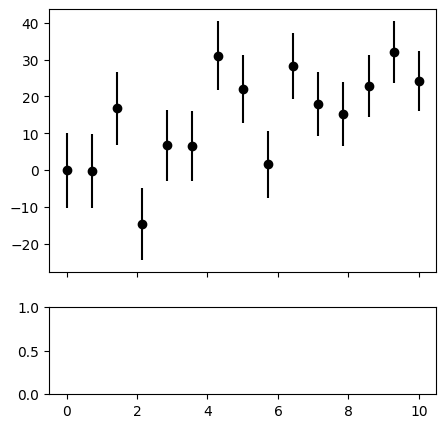

In [77]:
fig, (ax1,ax2) = plt.subplots(
    2,1,figsize=(5,5), sharex = True,
    gridspec_kw={'height_ratios': [3, 1]}
)
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', color='k')

In [78]:
# Programar minimos cuadrados ponderados
X = np.column_stack((np.ones(N),x))
X

array([[ 1.        ,  0.        ],
       [ 1.        ,  0.71428571],
       [ 1.        ,  1.42857143],
       [ 1.        ,  2.14285714],
       [ 1.        ,  2.85714286],
       [ 1.        ,  3.57142857],
       [ 1.        ,  4.28571429],
       [ 1.        ,  5.        ],
       [ 1.        ,  5.71428571],
       [ 1.        ,  6.42857143],
       [ 1.        ,  7.14285714],
       [ 1.        ,  7.85714286],
       [ 1.        ,  8.57142857],
       [ 1.        ,  9.28571429],
       [ 1.        , 10.        ]])

In [79]:
w = 1/sigma_y**2
w

array([0.00961169, 0.00988669, 0.01017366, 0.01047331, 0.01078639,
       0.01111373, 0.0114562 , 0.01181474, 0.01219039, 0.01258424,
       0.01299749, 0.01343143, 0.01388747, 0.01436714, 0.0148721 ])

In [80]:
# Ecuaciones de minimos cuadrados
A = X.T @ (w[:,None]*X)
B = X.T @ (w*y)

In [81]:
A

array([[0.17964667, 0.97281593],
       [0.97281593, 6.96624818]])

In [82]:
B

array([ 2.72840139, 19.47290189])

In [83]:
beta_hat = np.linalg.solve(A,B)
beta_hat

array([0.20705875, 2.76640616])

In [84]:
b,m = beta_hat
_x = np.linspace(0,10,100)
_y = b + m*_x

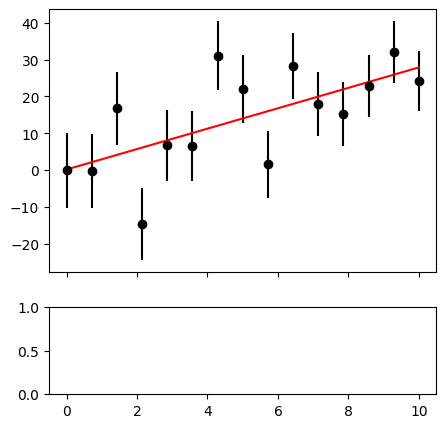

In [85]:
fig, (ax1,ax2) = plt.subplots(
    2,1,figsize=(5,5), sharex = True,
    gridspec_kw={'height_ratios': [3, 1]}
)
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', color='k')
ax1.plot(_x,_y,color='r')

In [86]:
# Queremos calcular el error en los modelos
C_beta = np.linalg.inv(A)
C_beta

array([[22.83323872, -3.18859417],
       [-3.18859417,  0.58882703]])

In [87]:
error_b, error_m = np.sqrt( np.diag(C_beta) )

In [88]:
print(b,error_b)

0.20705875076532468 4.778413829321127


In [89]:
print(m,error_m)

2.766406156474218 0.7673506537498684


In [93]:
y_fit = X @ beta_hat
residuos = y - y_fit
residuos_norm  = (y - y_fit)/sigma_y

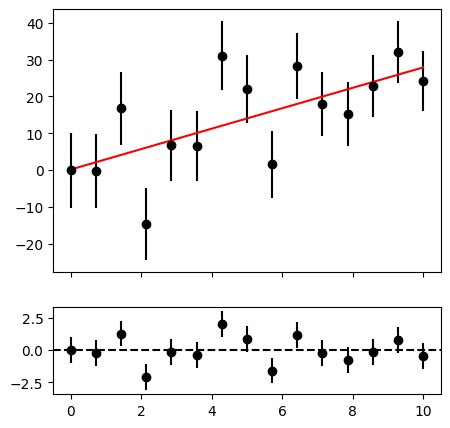

In [94]:
fig, (ax1,ax2) = plt.subplots(
    2,1,figsize=(5,5), sharex = True,
    gridspec_kw={'height_ratios': [3, 1]}
)
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', color='k')
ax1.plot(_x,_y,color='r')
ax2.errorbar(x, residuos_norm, yerr=1, fmt='o', color='k')
ax2.axhline(0, color='k', linestyle='--')